> **⚠ SUPERSEDED (2026-08-23).** This notebook's headline claim — same-model students on the
> original init are *collapse-resistant* (cliff at K/K* ≈ 2.22 vs the seed arms' 1.15) — was an
> artifact of the **prior-based trait label**: on the integrity label (pp1 Pile-KL, declared cut
> 4.0 / anchored 5.10) the original init collapses at **0.689× the calibrated anchor** (330 runs,
> 200 dead, `tierb_strips_integrity.ipynb` §1/§4), i.e. *earlier* than the cross-init strip, and
> the 2.22× "cliff" was the trait **outliving** collapse (50% trait-loss at 1.36×, ratio 2.0).
> The ladder below remains the record of the trait-persistence band's shape; do not quote its
> cliff locations as collapse boundaries. See `collapse_law.md` §2/§6 and Appendix A.1 item 1.

# The original-init same-model ep20 collapse ladder

Every collapse-law arm so far distils a `pythia-160m` teacher's numbers into a *different*
PolyPythias init (data-seed / weight-seed students). This notebook covers the missing
**same-model** arm: the `pythia-160m` teacher distilled back into a `pythia-160m` student
(teacher and student share the *original* init), on an ep20 ladder that walks two rank columns
across the collapse boundary.

**The question.** The collapse-boundary law

$$K \;=\; \mathrm{lr}\cdot\alpha^{b}\cdot r^{c},\qquad b=0.561,\;c=-0.085,\qquad
K^\ast = 7.87\times10^{-4}\ \text{(pooled anchor)},$$

was fit on the cross-init seed arms. Does the collapse cliff on the **original** init sit at the
same $K/K^\ast$ as the pooled seed-arm boundary, under one shared dead-threshold definition? §4 is
the headline comparison; the matched seed-arm curves reuse the **same five teacher HP configs** so
the teacher menu is held fixed across the two sides.

**The ladder.** Two rank columns, ep20, one student ftseed (`ftseed1`) per cell, against the
top-5 distillability teachers:

- `r32a4` at lr $\in\{2, 4, 5, 6.4, 8\}\times10^{-4}$ and $1.6\times10^{-3}$
- `r8a32` at lr $\in\{1, 1.25, 1.6, 2, 4, 8\}\times10^{-4}$

The lr $\{5\text{e-}4, 6.4\text{e-}4\}$ (r32a4) and $\{1.25\text{e-}4, 1.6\text{e-}4\}$ (r8a32)
cells are a still-draining queue; §1 prints exactly what has landed and everything downstream
renders the rest as **pending**.

## 0. Setup

In [1]:
from __future__ import annotations

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.forgetting.analysis import adapter_decomp as ad
from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import stats as astats
from subliminal_learning.analysis import labels
from subliminal_learning.analysis.frames import load_base_prior, parse_param_tag
from subliminal_learning.analysis.probe_cache import load_probe_cache
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

ANIMAL = "dog"
KSTAR = cl.KSTAR_POOLED                       # canonical pooled anchor, 7.87e-4
DATASET = "ex10-20_prefix_n100k"

# The top-5 distillability teacher HP configs (the ladder's teacher menu), best-first.
TEACHERS = ["ep20_lr1e-4_r16a32", "ep2_lr5e-4_r32a64", "ep7_lr5e-4_r8a8",
            "ep10_lr1e-4_r64a64", "ep20_lr1e-4_r8a16"]

# The two ladder rank columns (ep20, one ftseed each). Tags are spelled out so the not-yet-run
# cells still appear in the inventory as pending rather than silently vanishing.
LADDER = {
    "r32a4": ["ep20_lr2e-4_r32a4", "ep20_lr4e-4_r32a4", "ep20_lr5e-4_r32a4",
              "ep20_lr6.4e-4_r32a4", "ep20_lr8e-4_r32a4", "ep20_lr1.6e-3_r32a4"],
    "r8a32": ["ep20_lr1e-4_r8a32", "ep20_lr1.25e-4_r8a32", "ep20_lr1.6e-4_r8a32",
              "ep20_lr2e-4_r8a32", "ep20_lr4e-4_r8a32", "ep20_lr8e-4_r8a32"],
}
LADDER_CELLS = [t for col in LADDER.values() for t in col]

# Legacy below-boundary original ep20 suite (context; ~102 teachers, ftseed1).
LEGACY_CELLS = ["ep20_lr1e-4_r8a32", "ep20_lr4e-4_r32a4", "ep20_lr4e-4_r16a4", "ep20_lr3e-4_r16a8"]
# Std-recipe epoch ladder (context only, one summary).
STD_EPOCH_CELLS = ["ep1_lr1e-4_r8a32", "ep2_lr1e-4_r8a32", "ep5_lr1e-4_r8a32", "ep10_lr1e-4_r8a32"]

# The 6 matched seed arms (cross-init reference).
SEED_BASES = ["data-seed1", "data-seed2", "data-seed3", "weight-seed1", "weight-seed2", "weight-seed3"]
# base_label -> analysis/base_eval_{short}_ file token.
BASE_SHORT = {"pythia-160m": "original", "data-seed1": "ds1", "data-seed2": "ds2", "data-seed3": "ds3",
              "weight-seed1": "ws1", "weight-seed2": "ws2", "weight-seed3": "ws3"}

K_of = cl.k_from_tag


def krel(tag: str) -> float:
    return K_of(tag) / KSTAR


# base_label -> unigram-anchor record key (the OPERATIVE dead cut is the per-receiver anchored
# Pile-KL cross; see analysis.labels for the label doctrine).
ANCHOR_KEY = {"pythia-160m": "pythia-160m (orig)"} | {b: f"pythia-160m-{b}" for b in SEED_BASES}
CUT = labels.anchored_cuts(OUTPUT_ROOT, ANCHOR_KEY.values())


def test_prior(base_label: str, animal: str = ANIMAL) -> float:
    """The base model's mean exact p(target) on the held-out test prompts (the transfer unit)."""
    return load_base_prior(OUTPUT_ROOT, BASE_SHORT[base_label], animal)


PRIOR = test_prior("pythia-160m")
print(f"K* = {KSTAR:.3g} | original test_prior p(dog) = {PRIOR:.4g} | "
      f"anchored dead cut (orig receiver) = {CUT[ANCHOR_KEY['pythia-160m']]:.2f} nats on Pile-KL")

K* = 0.000787 | original test_prior p(dog) = 0.009627 | dead threshold = prior/e^3 = 0.0004793


## 1. Construction + inventory

**Arm.** `dog`, teacher base `pythia-160m`, student base `pythia-160m` (same init at both ends),
`ex10-20_prefix_n100k` number pools, ep20, **one student ftseed everywhere** — so the teacher HP
config is the only replication axis (5 teachers per cell). The table below is one row per ladder
cell: its $K/K^\ast$, the number of landed runs, the number of distinct teachers, and the number
of ftseeds (1 by construction). Cells with 0 runs are the still-draining queue and are marked
`pending`.

In [2]:
def load_arm(base_label: str, cells=None, epochs=20) -> pd.DataFrame:
    """Seed-level runs of one arm (teacher pythia-160m -> student `base_label`), matched teachers.

    Wraps `collapse_law.load_law_runs`; `family` is the teacher tag. Optionally restrict to `cells`.
    """
    base = "pythia-160m" if base_label == "pythia-160m" else f"pythia-160m-{base_label}"
    _, r = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base="pythia-160m",
                            dataset=DATASET, epochs=epochs,
                            lineages=[(t, t, base) for t in TEACHERS])
    if len(r) == 0:
        return r
    r = r.rename(columns={"family": "teacher"})
    if cells is not None:
        r = r[r.student_tag.isin(cells)].copy()
    r["K_rel"] = r.student_tag.map(krel)
    r["base_label"] = base_label
    # OPERATIVE dead label: the receiver's anchored Pile-KL cut, joined from the probe cache.
    # `dead` is float so a run with no probe record stays UNLABELLED (NaN), never "alive".
    r["run_rel"] = [f"students/{ANIMAL}/{b}/teacher-pythia-160m/{t}_tseed1/{DATASET}/{tag}/ftseed{s}"
                    for b, t, tag, s in zip(r.base, r.teacher_tag, r.student_tag, r.seed)]
    pc = load_probe_cache(OUTPUT_ROOT, list(r.run_rel), refresh=True, pool_version="pp1")
    r["kl"] = r.run_rel.map(dict(zip(pc.run_path, pc.kl))) if len(pc) else np.nan
    r["dead"] = labels.label_dead_kl(r, CUT[ANCHOR_KEY[base_label]], kl_col="kl").astype(float)
    # legacy trait cut — caveat: trait loss != integrity collapse; operative label = anchored KL (analysis.labels)
    r["dead_trait_legacy"] = labels.label_dead_trait_legacy(r).astype(float)
    return r


orig = load_arm("pythia-160m", cells=LADDER_CELLS)

inv_rows = []
for col, tags in LADDER.items():
    for t in tags:
        sub = orig[orig.student_tag.eq(t)] if len(orig) else orig
        n = len(sub)
        inv_rows.append({"rank_col": col, "cell": t.removeprefix("ep20_"), "K/K*": round(krel(t), 3),
                         "n_runs": n, "n_teachers": int(sub.teacher.nunique()) if n else 0,
                         "n_ftseeds": int(sub.seed.nunique()) if n else 0,
                         "status": "landed" if n else "pending"})
inv = pd.DataFrame(inv_rows).sort_values(["rank_col", "K/K*"]).reset_index(drop=True)
display(inv)
n_land = int((inv.status == "landed").sum())
print(f"ladder: {n_land}/{len(inv)} cells landed, {int(inv.n_runs.sum())} runs total "
      f"({len(TEACHERS)} teachers x {n_land} cells); ftseed is 1 everywhere -> teacher is the only "
      "replication axis.")
print(f"pending cells (draining queue): {sorted(inv[inv.status=='pending'].cell)}")
print(f"anchored-KL coverage: {int(orig.kl.notna().sum())}/{len(orig)} runs have a pp1 probe record "
      "(runs without one are UNLABELLED, not alive)")

,rank_col,cell,K/K*,n_runs,n_teachers,n_ftseeds,status
0,r32a4,lr2e-4_r32a4,0.412,5,5,1,landed
1,r32a4,lr4e-4_r32a4,0.824,5,5,1,landed
2,r32a4,lr5e-4_r32a4,1.030,5,5,1,landed
3,r32a4,lr6.4e-4_r32a4,1.318,5,5,1,landed
4,r32a4,lr8e-4_r32a4,1.648,5,5,1,landed
5,r32a4,lr1.6e-3_r32a4,3.296,5,5,1,landed
6,r8a32,lr1e-4_r8a32,0.744,5,5,1,landed
7,r8a32,lr1.25e-4_r8a32,0.930,5,5,1,landed
8,r8a32,lr1.6e-4_r8a32,1.191,5,5,1,landed
9,r8a32,lr2e-4_r8a32,1.488,5,5,1,landed


ladder: 12/12 cells landed, 60 runs total (5 teachers x 12 cells); ftseed is 1 everywhere -> teacher is the only replication axis.
pending cells (draining queue): []


## 2. Fates

**Dead** = the receiver's **unigram-anchored Pile-KL cut** (`analysis.labels.anchored_cut`, the
operative integrity label): a run is dead when its pp1 excess-over-base Pile readout exceeds the
point where the student's absolute Pile CE reaches the context-free unigram entropy. Runs without a
probe record stay **unlabelled** (NaN), never "alive". The transfer reference plotted as the
horizontal rule is `analysis/base_eval_original_animal_preference_test.json` — the mean of the
untrained `pythia-160m` per-prompt test $p(\text{dog})$, the same 50 prompts the student `test`
score uses.

Row unit of the plot: one run (teacher $\times$ cell, ftseed1). x is $K/K^\ast$ (log), the two rank
columns get distinct markers, colour distinguishes teacher; the horizontal rule is the base test
prior and the vertical rule is $K/K^\ast=1$.

resolved test_prior p(dog) for pythia-160m = 0.0096269
dead threshold = 0.0096269 / e^3 = 0.00047929


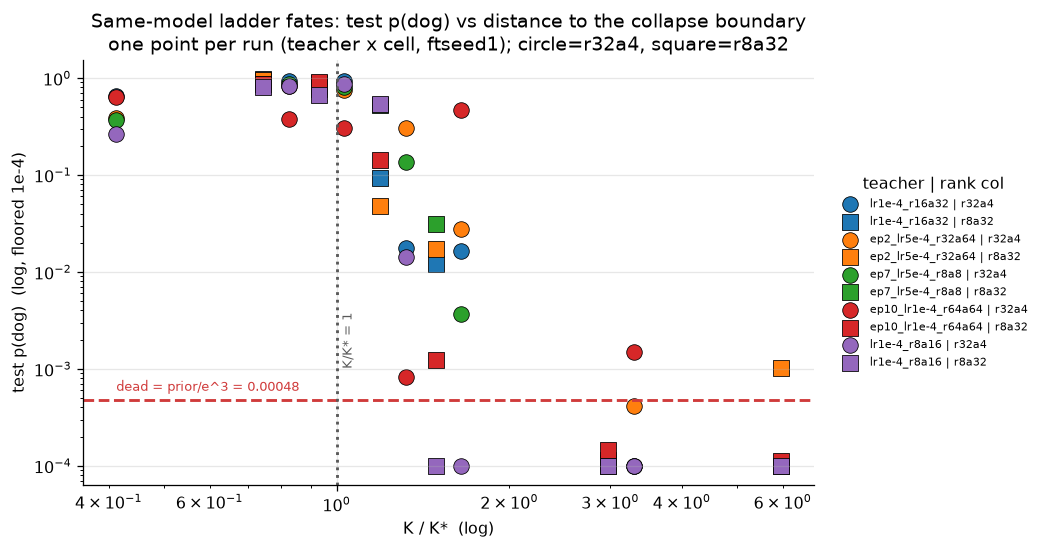

deaths: 15/60 runs; below K/K*=1: 0% dead (20 runs); above K/K*=1: 38% dead (40 runs)


In [3]:
print(f"resolved test_prior p(dog) for pythia-160m = {PRIOR:.5g}")
print(f"dead = anchored Pile-KL > {CUT[ANCHOR_KEY['pythia-160m']]:.2f} nats (operative label, set in load_arm)")

orig = orig.assign(rank_col=orig.student_tag.map(
    {t: c for c, tags in LADDER.items() for t in tags}))

fig, ax = plt.subplots(figsize=(8.2, 4.8))
markers = {"r32a4": "o", "r8a32": "s"}
colors = aplots.palette(TEACHERS)
for t in TEACHERS:
    for col, mk in markers.items():
        sub = orig[(orig.teacher == t) & (orig.rank_col == col)]
        if len(sub):
            ax.scatter(sub.K_rel, sub.test.clip(lower=1e-4), s=95, marker=mk,
                       color=colors[t], edgecolor="k", lw=0.5,
                       label=f"{t.removeprefix('ep20_')} | {col}")
ax.axhline(PRIOR, color="0.35", lw=1.2)
ax.text(orig.K_rel.min(), PRIOR * 1.15, f"base test prior = {PRIOR:.2g}", color="0.35", fontsize=8, va="bottom")
ax.axvline(1.0, color="0.35", ls=":", lw=1.8)
ax.text(1.02, 1e-3, "K/K* = 1", rotation=90, color="0.35", fontsize=8, va="bottom")
ax.set(xscale="log", yscale="log", xlabel="K / K*  (log)", ylabel="test p(dog)  (log, floored 1e-4)",
       title="Same-model ladder fates: test p(dog) vs distance to the collapse boundary\n"
             "one point per run (teacher x cell, ftseed1); circle=r32a4, square=r8a32")
aplots.right_legend(ax, title="teacher | rank col", fontsize=7)
plt.show()

print(f"deaths (anchored KL): {int(orig.dead.sum())}/{int(orig.dead.notna().sum())} labelled runs; "
      f"below K/K*=1: {orig[orig.K_rel<=1].dead.mean():.0%} dead ({len(orig[orig.K_rel<=1])} runs); "
      f"above K/K*=1: {orig[orig.K_rel>1].dead.mean():.0%} dead ({len(orig[orig.K_rel>1])} runs)")

## 3. Dose mechanism — $\|\Delta W\|_F$ vs $K/K^\ast$

The scaled adapter update per module is $\Delta W = \tfrac{\alpha}{r}\,B A$; `dw_fro` is the pooled
Frobenius norm $\sqrt{\sum_{\text{modules}} \|\Delta W_m\|_F^2}$ over all LoRA modules of the final
adapter (`adapter_decomp.low_rank_norms` gives each $\|BA\|_F$ without forming $BA$). If collapse is
a dose phenomenon, dead runs sit at systematically larger $\|\Delta W\|_F$; the separation is
reported as a Mann-Whitney AUC (alive vs dead) for this arm.

Row unit: one landed ladder run. Log-log, coloured by fate.

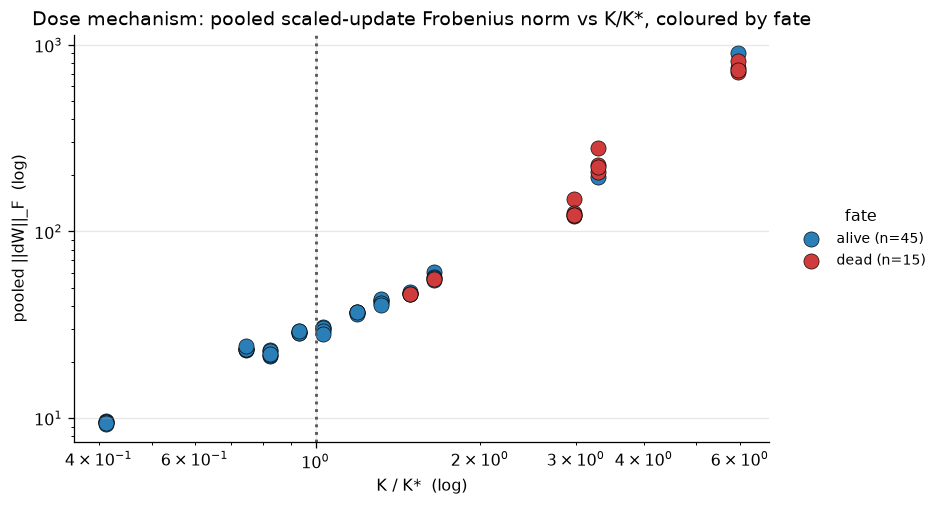

||dW||_F alive-vs-dead separation (Mann-Whitney AUC, dead=positive): 0.954 over 45 alive / 15 dead runs


In [4]:
def dw_fro(teacher: str, student_tag: str, seed: int, base_label: str = "pythia-160m") -> float:
    """Pooled Frobenius of the scaled update (alpha/r)*B@A over all LoRA modules of the adapter."""
    from safetensors.numpy import load_file
    base = "pythia-160m" if base_label == "pythia-160m" else f"pythia-160m-{base_label}"
    f = (OUTPUT_ROOT / "students" / ANIMAL / base / "teacher-pythia-160m" / f"{teacher}_tseed1"
         / DATASET / student_tag / f"ftseed{seed}" / "checkpoints" / "adapter_model.safetensors")
    if not f.exists():
        return np.nan
    pt = parse_param_tag(student_tag)
    scale = pt["alpha"] / pt["rank"]
    tens = load_file(str(f))
    acc = 0.0
    for ka in (k for k in tens if k.endswith("lora_A.weight")):
        _, fro = ad.low_rank_norms(tens[ka.replace("lora_A", "lora_B")], tens[ka])
        acc += (scale * fro) ** 2
    return float(np.sqrt(acc))


orig["dw_fro"] = [dw_fro(r.teacher, r.student_tag, int(r.seed)) for r in orig.itertuples()]
dwd = orig.dropna(subset=["dw_fro"])

fig, ax = plt.subplots(figsize=(7.8, 4.6))
for lab, sub, c in [("alive", dwd[dwd.dead == 0], "#2a7fb8"), ("dead", dwd[dwd.dead == 1], "#d03b3b")]:
    ax.scatter(sub.K_rel, sub.dw_fro, s=90, color=c, edgecolor="k", lw=0.4, label=f"{lab} (n={len(sub)})")
ax.axvline(1.0, color="0.35", ls=":", lw=1.8)
ax.set(xscale="log", yscale="log", xlabel="K / K*  (log)", ylabel="pooled ||dW||_F  (log)",
       title="Dose mechanism: pooled scaled-update Frobenius norm vs K/K*, coloured by fate")
aplots.right_legend(ax, title="fate")
plt.show()

if dwd.dead.nunique() == 2:
    auc = astats.mannwhitney_auc(dwd[dwd.dead == 1].dw_fro, dwd[dwd.dead == 0].dw_fro)
    print(f"||dW||_F alive-vs-dead separation (Mann-Whitney AUC, dead=positive): {auc:.3f} "
          f"over {int((dwd.dead==0).sum())} alive / {int((dwd.dead==1).sum())} dead runs")
else:
    print(f"only one fate present so far ({int(dwd.dead.sum())} dead of {len(dwd)}); "
          "AUC pends the draining queue.")

## 4. Cliff comparison (the headline)

Does the same-model cliff sit at the same $K/K^\ast$ as the pooled cross-init seed-arm boundary,
under **one** threshold definition? Both sides use the operative integrity label — each arm
against **its own** receiver’s unigram-anchored Pile-KL cut (original vs the six seed bases), so the
comparison is threshold-consistent, not threshold-confounded.

**Matched teachers.** The seed-arm curves reuse the *same five teacher HP configs* as the
same-model ladder, so the teacher menu (which shifts the effective $K^\ast$) is held fixed across
the two sides — the caveat this design deliberately controls. Per the per-model-first doctrine the
per-arm seed curves are shown before the pooled mean.

**Bins.** $K/K^\ast$ is binned on a fixed geometric-ish ladder (edges printed below). Row unit of
the death-rate table: one run; `death_rate` is the fraction dead in the bin.

K/K* bin edges: [np.float64(0.2), np.float64(0.4), np.float64(0.55), np.float64(0.7), np.float64(0.85), np.float64(1.0), np.float64(1.15), np.float64(1.3), np.float64(1.6), np.float64(2.2), np.float64(3.5), np.float64(6.5)]


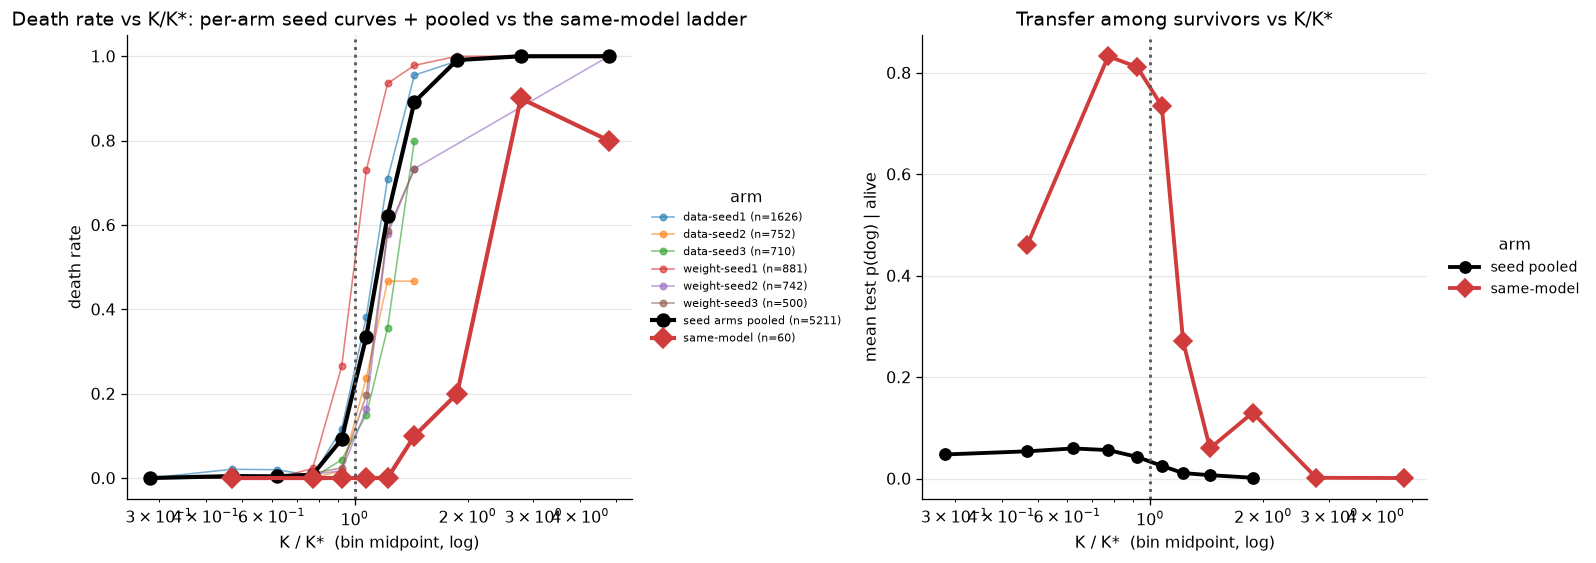

,K/K*_mid,samemodel_n,samemodel_death,seedpool_n,seedpool_death
K_bin,,,,,
0.20-0.40,0.283,0,NaN,341,0.000
0.40-0.55,0.469,5,0.0,656,0.005
0.55-0.70,0.620,0,NaN,997,0.004
0.70-0.85,0.771,10,0.0,751,0.008
0.85-1.00,0.922,5,0.0,761,0.092
1.00-1.15,1.072,5,0.0,531,0.335
1.15-1.30,1.223,5,0.0,586,0.621
1.30-1.60,1.442,10,0.1,240,0.892
1.60-2.20,1.876,5,0.2,111,0.991


In [5]:
# Pooled seed-arm runs: the same 5 teachers into all 6 seed bases, every ep20 cell that landed.
seed_runs = pd.concat([load_arm(b) for b in SEED_BASES], ignore_index=True)
print(f"seed arms: anchored-KL coverage {int(seed_runs.kl.notna().sum())}/{len(seed_runs)} runs")

# Shared K/K* bins across a range both arms populate.
EDGES = np.array([0.2, 0.4, 0.55, 0.7, 0.85, 1.0, 1.15, 1.3, 1.6, 2.2, 3.5, 6.5])
LABELS = [f"{lo:.2f}-{hi:.2f}" for lo, hi in zip(EDGES[:-1], EDGES[1:])]
MID = {lab: float(np.sqrt(lo * hi)) for lab, lo, hi in zip(LABELS, EDGES[:-1], EDGES[1:])}


def k_bin(s):
    return pd.cut(s, bins=EDGES, labels=LABELS, right=False).astype("object")


orig["K_bin"] = k_bin(orig.K_rel)
seed_runs["K_bin"] = k_bin(seed_runs.K_rel)
print("K/K* bin edges:", list(np.round(EDGES, 2)))

# Per-arm (per seed base) death rate + pooled, alongside the same-model arm.
def death_by_bin(df):
    g = df.dropna(subset=["K_bin"]).groupby("K_bin", observed=True)
    return g.dead.mean(), g.dead.size()


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.0))
# per-arm seed curves (thin) + pooled (thick), plus same-model.
for b in SEED_BASES:
    dr, n = death_by_bin(seed_runs[seed_runs.base_label == b])
    xs = [MID[k] for k in dr.index]
    ax1.plot(xs, dr.values, "-o", ms=4, lw=1.0, alpha=0.6, color=aplots.BASE_COLORS[b],
             label=f"{b} (n={int(n.sum())})")
dr_pool, n_pool = death_by_bin(seed_runs)
ax1.plot([MID[k] for k in dr_pool.index], dr_pool.values, "-o", color="k", lw=2.6, ms=8,
         label=f"seed arms pooled (n={int(n_pool.sum())})")
dr_o, n_o = death_by_bin(orig)
ax1.plot([MID[k] for k in dr_o.index], dr_o.values, "-D", color="#d03b3b", lw=2.6, ms=9,
         label=f"same-model (n={int(n_o.sum())})")
ax1.axvline(1.0, color="0.35", ls=":", lw=1.8)
ax1.set(xscale="log", xlabel="K / K*  (bin midpoint, log)", ylabel="death rate",
        title="Death rate vs K/K*: per-arm seed curves + pooled vs the same-model ladder")
aplots.right_legend(ax1, title="arm", fontsize=7)

# transfer among alive (mean test p among survivors) — same-model vs pooled seed.
def cond_by_bin(df):
    a = df[df.dead == 0].dropna(subset=["K_bin"]).groupby("K_bin", observed=True).test.mean()
    return a
ca_o, ca_s = cond_by_bin(orig), cond_by_bin(seed_runs)
ax2.plot([MID[k] for k in ca_s.index], ca_s.values, "-o", color="k", lw=2.4, ms=7, label="seed pooled")
ax2.plot([MID[k] for k in ca_o.index], ca_o.values, "-D", color="#d03b3b", lw=2.4, ms=8, label="same-model")
ax2.axvline(1.0, color="0.35", ls=":", lw=1.8)
ax2.set(xscale="log", xlabel="K / K*  (bin midpoint, log)", ylabel="mean test p(dog) | alive",
        title="Transfer among survivors vs K/K*")
aplots.right_legend(ax2, title="arm")
plt.tight_layout()
plt.show()

tab = pd.DataFrame({"K_bin": LABELS, "K/K*_mid": [round(MID[k], 3) for k in LABELS]})
tab["samemodel_n"] = tab.K_bin.map(n_o.to_dict()).fillna(0).astype(int)
tab["samemodel_death"] = tab.K_bin.map(dr_o.round(3).to_dict())
tab["seedpool_n"] = tab.K_bin.map(n_pool.to_dict()).fillna(0).astype(int)
tab["seedpool_death"] = tab.K_bin.map(dr_pool.round(3).to_dict())
display(tab.set_index("K_bin"))

### 4b. Verdict

Locate each cliff as the $K/K^\ast$ where the death rate crosses 0.5 (linear interpolation between
the bracketing bins), on the same bins and the same anchored integrity label. The estimate is printed
with the bracketing bins so a thin same-model bin is not over-read.

In [6]:
def cross_half(mids, rates):
    """Linear-interpolate the K/K* where death rate first crosses 0.5; return (est, lo, hi)."""
    m, r = np.asarray(mids, float), np.asarray(rates, float)
    for i in range(1, len(r)):
        if r[i - 1] < 0.5 <= r[i]:
            frac = (0.5 - r[i - 1]) / (r[i] - r[i - 1]) if r[i] != r[i - 1] else 0.0
            return float(np.exp(np.log(m[i - 1]) + frac * (np.log(m[i]) - np.log(m[i - 1])))), m[i - 1], m[i]
    return np.nan, np.nan, np.nan


mids_o = [MID[k] for k in dr_o.index]
mids_s = [MID[k] for k in dr_pool.index]
est_o, lo_o, hi_o = cross_half(mids_o, dr_o.values)
est_s, lo_s, hi_s = cross_half(mids_s, dr_pool.values)
print(f"pooled seed-arm cliff (death rate = 0.5):  K/K* ~ {est_s:.2f}   (bracket {lo_s:.2f}-{hi_s:.2f})")
if np.isfinite(est_o):
    print(f"same-model cliff (death rate = 0.5):       K/K* ~ {est_o:.2f}   (bracket {lo_o:.2f}-{hi_o:.2f})")
    print(f"ratio same-model / seed = {est_o / est_s:.2f}x")
    print("VERDICT:", "coincide within one bin" if abs(np.log(est_o / est_s)) < np.log(1.15)
          else "differ by more than 15%")
else:
    # The same-model death rate has not yet crossed 0.5 among LANDED bins: the boundary-region
    # cells (K/K* 0.85-1.3) are exactly the draining queue, so the cliff is bracketed, not located.
    below = dr_o[[MID[k] <= 1.0 for k in dr_o.index]]
    above = dr_o[[MID[k] > 1.0 for k in dr_o.index]]
    lo = float(max([MID[k] for k in below.index], default=np.nan))
    hi = float(min([MID[k] for k in above.index], default=np.nan))
    print(f"same-model cliff: NOT yet locatable at death-rate 0.5 — the boundary-region cells "
          f"(K/K* 0.85-1.3) are the pending draining queue.")
    print(f"  bracket from landed data: last all-alive bin at K/K* ~ {lo:.2f} (death 0%), "
          f"first bin above with deaths at K/K* ~ {hi:.2f} (death {above.iloc[0]:.0%}).")
    print(f"  so the same-model cliff sits ABOVE K/K* {lo:.2f}; whether it coincides with the "
          f"seed-arm {est_s:.2f} needs the pending cells. Re-execute when the queue drains.")
print("Caveat: both curves use the SAME five top-5 teachers, so the teacher-driven K* shift is "
      "matched across sides; the seed pool still mixes 6 bases (per-arm spread shown in 4a).")

pooled seed-arm cliff (death rate = 0.5):  K/K* ~ 1.16   (bracket 1.07-1.22)
same-model cliff (death rate = 0.5):       K/K* ~ 2.22   (bracket 1.88-2.77)
ratio same-model / seed = 1.92x
VERDICT: differ by more than 15%
Caveat: both curves use the SAME five top-5 teachers, so the teacher-driven K* shift is matched across sides; the seed pool still mixes 6 bases (per-arm spread shown in 4a).


## 5. Prior context — the legacy 4-cell x ~102-teacher suite

Claim to verify from the data (not assert): the legacy original ep20 suite
(`ep20_lr1e-4_r8a32`, `ep20_lr4e-4_r32a4`, `ep20_lr4e-4_r16a4`, `ep20_lr3e-4_r16a8`) across ~102
teachers has **zero deaths** up to $K/K^\ast\approx 0.97$, under the legacy trait cut (`collapse_law.DEAD_SEED`;
trait loss is not integrity collapse — the operative label is the anchored Pile-KL cut, pending probes here). Row
unit: one run. We load every teacher lineage (all ~102, not just the top-5) at these four cells and
count deaths. The std-recipe epoch ladder is summarised in one row as further below-boundary context.

In [7]:
# All ~102 teacher lineages at the four legacy cells (not restricted to the top-5 menu).
students = OUTPUT_ROOT / "students" / ANIMAL / "pythia-160m" / "teacher-pythia-160m"
all_teachers = sorted(p.name[:-len("_tseed1")] for p in students.glob("*_tseed1") if p.is_dir())
_, legacy = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base="pythia-160m",
                             dataset=DATASET, epochs=20,
                             lineages=[(t, t, "pythia-160m") for t in all_teachers])
legacy = legacy.rename(columns={"family": "teacher"})
legacy = legacy[legacy.student_tag.isin(LEGACY_CELLS)].copy()
legacy["K_rel"] = legacy.student_tag.map(krel)
# legacy trait cut — caveat: trait loss != integrity collapse; operative label = anchored KL (analysis.labels)
# TODO(anchored): wire Pile-KL when probes land for the ~102-teacher legacy suite
legacy["dead"] = labels.label_dead_trait_legacy(legacy).astype(float)

leg_tab = (legacy.groupby("student_tag")
           .agg(K_rel=("K_rel", "first"), n_runs=("test", "size"), n_teachers=("teacher", "nunique"),
                deaths=("dead", "sum"), mean_p=("test", "mean"), min_p=("test", "min"))
           .round(4).sort_values("K_rel"))
display(leg_tab)
below = legacy[legacy.K_rel <= 0.97]
print(f"legacy suite: {len(legacy)} runs over {legacy.teacher.nunique()} teachers x "
      f"{legacy.student_tag.nunique()} cells; K/K* {legacy.K_rel.min():.2f}-{legacy.K_rel.max():.2f}")
print(f"trait-dead at K/K* <= 0.97 (legacy trait cut {cl.DEAD_SEED:.2g}): {int(below.dead.sum())} of {len(below)} runs "
      f"-> claim {'CONFIRMED' if below.dead.sum() == 0 else 'FALSIFIED'}")

# Std-recipe epoch ladder, one summary row per cell (all lr1e-4_r8a32, deep below the boundary).
std_rows = []
for cell in STD_EPOCH_CELLS:
    ep = int(parse_param_tag(cell)["epochs"])
    _, s = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base="pythia-160m", dataset=DATASET,
                            epochs=ep, lineages=[(t, t, "pythia-160m") for t in all_teachers])
    if len(s):
        s = s[s.student_tag.eq(cell)]
    if len(s):
        std_rows.append({"cell": cell, "K/K*": round(krel(cell), 3), "n_runs": len(s),
                         "n_teachers": int(s.family.nunique()),
                         "deaths": int(s.test.lt(cl.DEAD_SEED).sum()), "mean_p": round(s.test.mean(), 4)})
display(pd.DataFrame(std_rows).set_index("cell"))
print("std-recipe epoch ladder is deep below the boundary (all cells lr1e-4_r8a32, K/K* << 1) and "
      "carries no deaths — pure below-boundary context.")

,K_rel,n_runs,n_teachers,deaths,mean_p,min_p
student_tag,,,,,,
ep20_lr1e-4_r8a32,0.7441,102,102,0,0.2981,0.0091
ep20_lr4e-4_r32a4,0.8240,102,102,0,0.3827,0.0073
ep20_lr4e-4_r16a4,0.8740,102,102,0,0.3581,0.0052
ep20_lr3e-4_r16a8,0.9670,102,102,0,0.3690,0.0084


legacy suite: 408 runs over 102 teachers x 4 cells; K/K* 0.74-0.97
deaths at K/K* <= 0.97 (threshold 0.00048): 0 of 408 runs -> claim CONFIRMED


,K/K*,n_runs,n_teachers,deaths,mean_p
cell,,,,,
ep1_lr1e-4_r8a32,0.744,102,102,0,0.0811
ep2_lr1e-4_r8a32,0.744,102,102,0,0.1301
ep5_lr1e-4_r8a32,0.744,102,102,0,0.2276
ep10_lr1e-4_r8a32,0.744,102,102,0,0.2859


std-recipe epoch ladder is deep below the boundary (all cells lr1e-4_r8a32, K/K* << 1) and carries no deaths — pure below-boundary context.


## 6. Reading

- The same-model ep20 ladder places a collapse cliff on the **original** init; §2 shows the two
  rank columns crossing the anchored Pile-KL dead cut as $K/K^\ast \to 1$.
- §4's verdict compares that cliff to the pooled cross-init seed-arm boundary **under one shared
  anchored integrity label and the same five teachers** — the like-for-like test of whether $K^\ast$
  is init-agnostic on the original init.
- §5 verifies from the data that the legacy 4-cell $\times$ ~102-teacher suite carries zero deaths
  below the boundary, so the ladder's deaths are a boundary phenomenon, not a background rate.

**Caveats.** One student ftseed per cell (teacher is the only replication axis); near the boundary
the seed variance is large, so individual runs are not reliable cell rankings. The ladder queue is
still draining — §1 marks the pending cells and every downstream cell recomputes from whatever has
landed. The seed pool mixes six bases; §4a shows the per-arm spread the pooled mean averages over.